## Step 2 — Data collection and understanding

Place the supplied file at `data/creditcard.csv` (or update `DATA_PATH` below). The file has 284,807 rows and 31 columns. It contains:
- `Time`: seconds elapsed between each transaction and the first transaction in the dataset.
- `Amount`: transaction amount (currency unit is not specified in this file).
- `V1`–`V28`: anonymised numerical features produced by a PCA transformation. Their original business meanings are not supplied.
- `Class`: target label (0 legitimate, 1 fraud).

### Data dictionary

| Variable | Type | Meaning / allowed values |
|---|---|---|
| Time | Numeric (float) | Elapsed seconds; non-negative in this dataset |
| V1–V28 | Numeric (float) | Anonymised PCA-transformed features; continuous |
| Amount | Numeric (float) | Transaction amount; non-negative |
| Class | Binary integer | 0 = legitimate, 1 = fraud |

The notebook checks actual missing values, duplicates, data types, ranges, and class balance rather than assuming they are absent.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

In [6]:
df = pd.read_csv("/Users/saviam/Desktop/Sessions/AI ML AIM/Datasets/Capstone_Project/creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [14]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()


print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (284807, 31)

Column Names:
Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-nul

### Initial data-quality interpretation

The benchmark dataset supplied for this project has 284,807 records, 31 columns, and no missing values. It contains 492 fraud cases. This means fraud represents only about 0.173% of all observations. Always rerun the checks above if the dataset is replaced or modified.

Exact duplicates should be investigated before removal. In this benchmark, a duplicate may represent a repeated row, but in real payment data two genuinely separate transactions can share the same observed values. Do not automatically delete duplicates without understanding transaction identifiers and business rules.

# Step 3 — Preprocessing, applied EDA and feature engineering

Class
0    284315
1       492
Name: count, dtype: int64


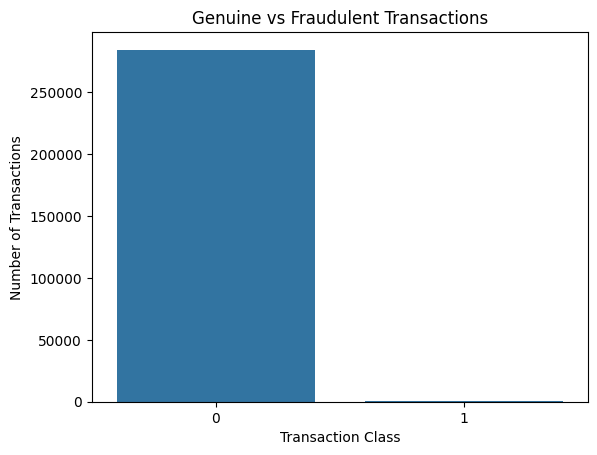

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [16]:
print(df["Class"].value_counts())

sns.countplot(x="Class", data=df)
plt.title("Genuine vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.show()


fraud_percentage = df["Class"].value_counts(normalize=True) * 100

print(fraud_percentage)

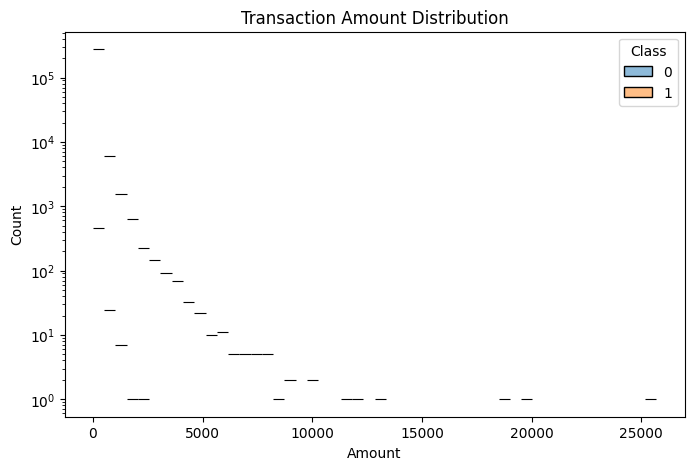

In [18]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True)
)

plt.title("Transaction Amount Distribution")
plt.show()

Interpretation: Fraudulent transactions are extremely rare compared with genuine transactions. This is called an imbalanced dataset.

This imbalance is important because a model could predict every transaction as genuine and still achieve very high accuracy.

In [38]:
#Data preprocessing and feature engineering
#Separate the independent variables (X) and dependent variable (y).

X = df.drop("Class", axis=1)
y = df["Class"]

#Create two additional features:
#log_amount: Reduces the impact of highly skewed transaction amounts.
# hour_proxy: Converts transaction time into an approximate time-of-day feature

X["log_amount"] = np.log1p(X["Amount"])

X["hour_proxy"] = (X["Time"] / 3600) % 24

X = X.drop(["Amount", "Time"], axis=1)



X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (227845, 30)
Testing Data: (56962, 30)


In [44]:
#Featurescaling: Logistic Regression performs better when features are on comparable scales.

#We fit the scaler only on the training data to avoid data leakage.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [46]:
#Build the machine learning models
#We will compare two models:
#1. Logistic Regression – a simple classification model.
#2. Random Forest – an ensemble model that combines multiple decision trees.
#Both models use class weighting to give greater importance to the minority fraud class.


lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

In [49]:
#Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [57]:
# Logistic Regression probabilities
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]

# Random Forest probabilities
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]


# Evaluate Logistic Regression
evaluate_model(
    y_test,
    lr_predictions,
    lr_probabilities,
    "Logistic Regression"
)


# Evaluate Random Forest
evaluate_model(
    y_test,
    rf_predictions,
    rf_probabilities,
    "Random Forest"
)


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.91      0.10        98

    accuracy                           0.97     56962
   macro avg       0.53      0.94      0.55     56962
weighted avg       1.00      0.97      0.98     56962

Precision: 0.055074257425742575
Recall: 0.9081632653061225
F1 Score: 0.10385064177362893
ROC-AUC: 0.97097020962296
Average Precision: 0.7129809410287019

Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Precision: 0.96
Recall: 0.7346938775510204
F1 Score: 0.8323699421965318
ROC-AUC: 0.963105849402

In [61]:
#Evaluate model performance
#For fraud detection, accuracy alone is not sufficient.

#We should focus on:
#- Precision: Of all transactions predicted as fraud, how many were actually fraudulent?
#- Recall: Of all actual fraudulent transactions, how many did the model identify?
#- F1-score: A balance between precision and recall.
#- ROC-AUC: Measures how well the model separates the two classes.
#- Average Precision: Summarises the precision-recall performance and is particularly useful for imbalanced datasets.

#We can Create an evaluation function:

from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Generate predicted class labels
y_pred = rf_model.predict(X_test)

# Generate predicted probabilities for fraud (Class 1)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate Random Forest
evaluate_model(
    y_test,
    y_pred,
    y_prob,
    "Random Forest"
)


Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Precision: 0.96
Recall: 0.7346938775510204
F1 Score: 0.8323699421965318
ROC-AUC: 0.9631058494022257
Average Precision: 0.8571550533410666


In [63]:
#Evaluate LR
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]

evaluate_model(
    y_test,
    lr_predictions,
    lr_probabilities,
    "Logistic Regression"
)


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.91      0.10        98

    accuracy                           0.97     56962
   macro avg       0.53      0.94      0.55     56962
weighted avg       1.00      0.97      0.98     56962

Precision: 0.055074257425742575
Recall: 0.9081632653061225
F1 Score: 0.10385064177362893
ROC-AUC: 0.97097020962296
Average Precision: 0.7129809410287019


In [65]:
#Evaluate RF

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

evaluate_model(
    y_test,
    rf_predictions,
    rf_probabilities,
    "Random Forest"
)


Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Precision: 0.96
Recall: 0.7346938775510204
F1 Score: 0.8323699421965318
ROC-AUC: 0.9631058494022257
Average Precision: 0.8571550533410666


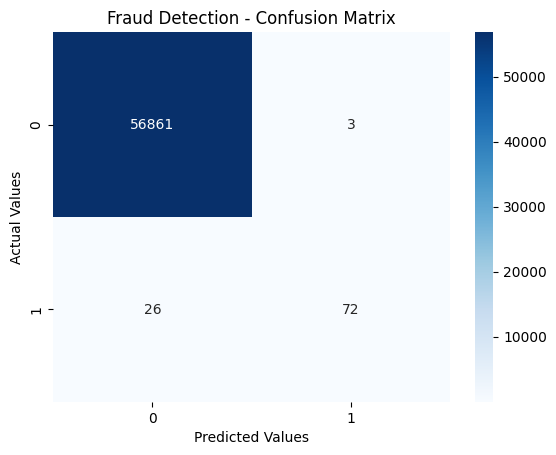

In [67]:
cm = confusion_matrix(y_test, rf_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Fraud Detection - Confusion Matrix")
plt.show()

In [ ]:
##Classification	Meaning: as per above matrix
#True Positive (TP)	Fraud correctly identified
#True Negative (TN)	Genuine transaction correctly identified
#False Positive (FP)	Genuine transaction incorrectly flagged as fraud
#False Negative (FN)	Fraud transaction incorrectly classified as genuine

#Business interpretation: False negatives are particularly important because they represent fraudulent transactions that the bank failed to detect. 
#False positives also matter because they can inconvenience genuine customers.

In [69]:
#Identify important features
#Random Forest can help us understand which variables contribute most to predictions.
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10))

   Feature  Importance
13     V14    0.214892
9      V10    0.109782
3       V4    0.106908
16     V17    0.088001
11     V12    0.075584
10     V11    0.073024
2       V3    0.069438
15     V16    0.036963
6       V7    0.029294
1       V2    0.026368


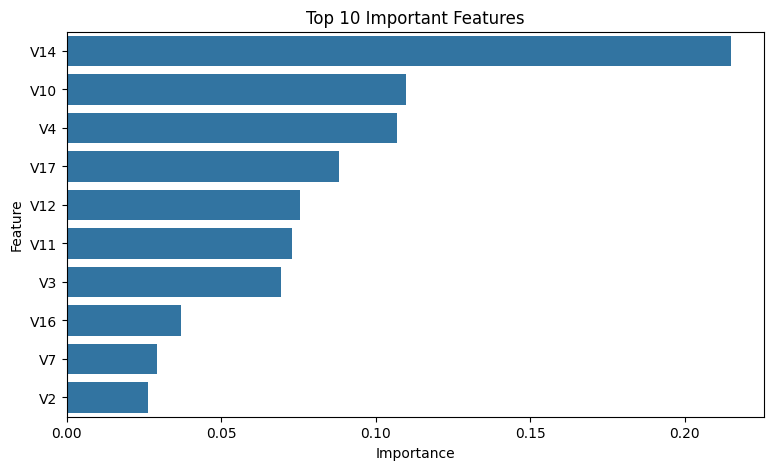

In [73]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.show()

   Feature  Importance
13     V14    0.018916
3       V4    0.018381
11     V12    0.017881
16     V17    0.016525
17     V18    0.010097
2       V3    0.009963
15     V16    0.008189
27     V28    0.006663
5       V6    0.006244
21     V22    0.006212


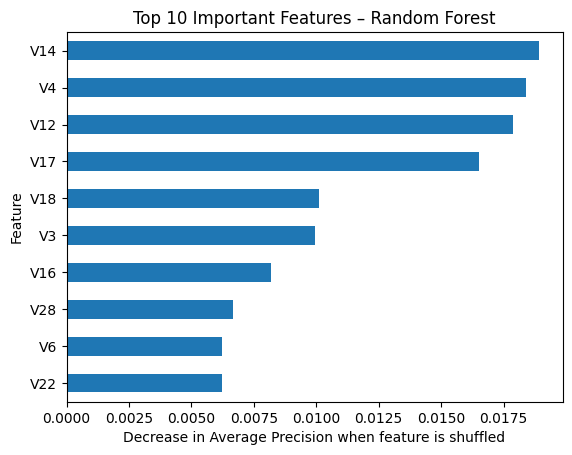

In [79]:
## Step 5 — Critical thinking, ethical AI and bias auditing

### 5.1 Model risks and limitations
#Class imbalance:** only 492 of 284,807 transactions are fraud. Accuracy can conceal failure on the minority class.
#False negatives:** undetected fraud creates direct loss.
#False positives:** legitimate customers may experience declined transactions, delays, or account restrictions.
#Data leakage:** preprocessing, feature selection, oversampling, and threshold selection must not use the test set.
#Overfitting:** compare training and validation performance; use cross-validation or a later chronological holdout before deployment.
#Concept drift:** fraud patterns and attacker behaviour change. Monitor performance and retrain under controlled governance.
#Limited semantics:** `V1`–`V28` are anonymised; business interpretation is constrained.
#Dataset representativeness:** this benchmark may not reflect current payment channels, geography, customer mix, or operational costs.

# 5.2 Fairness audit — what can and cannot be concluded
#The supplied file has no gender, age, race, socioeconomic, or other protected-group columns. Therefore, demographic parity, equalised odds, and disparate-impact ratios **cannot be calculated from this dataset**. Do not fabricate group results or infer sensitive attributes from anonymised PCA features.

#For an approved real-world audit:
#1. Obtain legally authorised and purpose-limited demographic attributes, with privacy safeguards.
#2. Define groups and intersectional cohorts with sufficient sample sizes.
#3. Compare selection/flag rates, TPR (equal opportunity), FPR, precision, and calibration across groups.
#4. Quantify uncertainty with confidence intervals; investigate base-rate and data-quality differences.
#5. Consider mitigations such as representative data collection, reweighting, threshold review, human review, and post-processing—subject to legal and governance review.
#6. Document residual trade-offs. Fairness metrics can conflict; no single metric proves a system is fair.

#5.3 Human oversight
#Treat the model as a decision-support tool. High-risk alerts should follow documented review and escalation procedures. 
#Maintain appeal/correction routes, access controls, audit logs, and monitoring for drift and disparate impact.


from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate feature importance
importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="average_precision",
    n_jobs=-1
)

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
})

# Display the top 10 important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

# Plot feature importance
importance_df.head(10).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("Top 10 Important Features – Random Forest")
plt.xlabel("Decrease in Average Precision when feature is shuffled")
plt.gca().invert_yaxis()
plt.show()

#Above Interpretation: If shuffling a feature reduces model performance significantly, that feature is important to the model's predictions. This shows association with model performance, not necessarily a causal relationship.

In [82]:
#Check model limitations

limitations = {
    "Class imbalance": "Only 492 out of 284,807 transactions are fraudulent.",
    "Data leakage": "Scaler and preprocessing steps must be fitted on training data only.",
    "Overfitting": "Compare training, validation and test performance.",
    "Limited demographic data": "The dataset does not contain gender, race, age or socioeconomic status.",
    "Anonymised features": "V1 to V28 are transformed features and are difficult to interpret directly."
}

for issue, explanation in limitations.items():
    print("\n", issue)
    print(explanation)


 Class imbalance
Only 492 out of 284,807 transactions are fraudulent.

 Data leakage
Scaler and preprocessing steps must be fitted on training data only.

 Overfitting
Compare training, validation and test performance.

 Limited demographic data
The dataset does not contain gender, race, age or socioeconomic status.

 Anonymised features
V1 to V28 are transformed features and are difficult to interpret directly.


In [84]:
#Bias detection and fairness audit
#Important finding for this dataset: The credit card dataset does not contain gender, race, age or socioeconomic status. 
#Therefore, we cannot calculate demographic parity, equalised odds or disparate impact across these groups using the available data.

#First, check whether sensitive attributes are available:


sensitive_columns = [
    "Gender",
    "Race",
    "Age",
    "Socioeconomic_Status"
]

available_columns = [
    col for col in sensitive_columns
    if col in X_test.columns
]

if len(available_columns) == 0:
    print("Fairness audit cannot be completed by demographic group.")
    print("Sensitive demographic attributes are not available.")
else:
    print("Available sensitive attributes:", available_columns)

Fairness audit cannot be completed by demographic group.
Sensitive demographic attributes are not available.


In [99]:
print(X_test.columns.tolist())

['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'log_amount', 'hour_proxy']


In [101]:
# Divide transactions into three categories
groups = pd.qcut(
    X_test['log_amount'],
    q=3,
    labels=["Low", "Medium", "High"]
)

# Execute fairness audit
fairness_results = fairness_audit(
    y_test,
    rf_predictions,
    groups
)

# Display results
print("Credit Card Fraud Detection - Fairness Audit")
display(fairness_results)

Credit Card Fraud Detection - Fairness Audit


,Group,Selection Rate,True Positive Rate,False Positive Rate
0,Medium,0.000380,0.636364,0.000000
1,High,0.001528,0.763158,0.000000
2,Low,0.001992,0.734694,0.000154


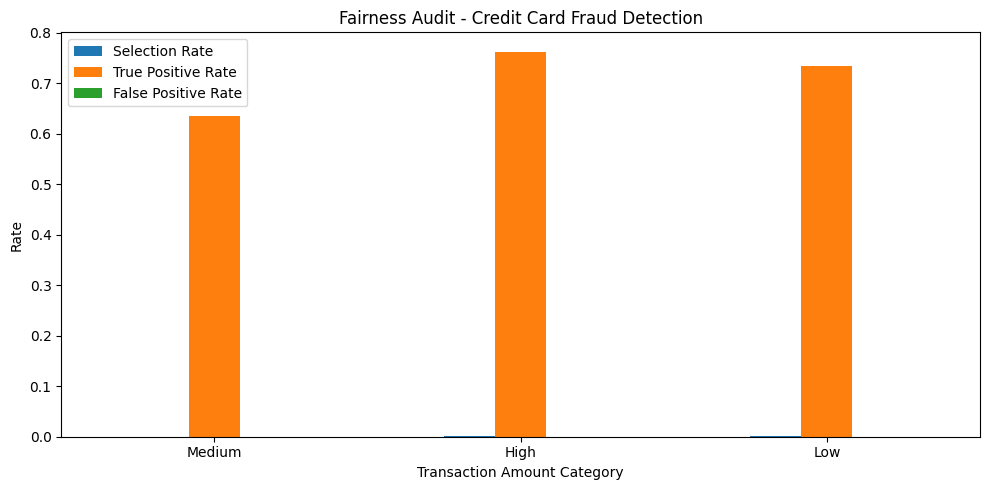

In [109]:
import matplotlib.pyplot as plt

fairness_results.set_index("Group").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Fairness Audit - Credit Card Fraud Detection")
plt.ylabel("Rate")
plt.xlabel("Transaction Amount Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [112]:
from sklearn.metrics import classification_report, confusion_matrix

# Model performance
print("Classification Report:")
print(classification_report(y_test, rf_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56861     3]
 [   26    72]]


In [114]:
display(fairness_results.round(4))

,Group,Selection Rate,True Positive Rate,False Positive Rate
0,Medium,0.0004,0.6364,0.0000
1,High,0.0015,0.7632,0.0000
2,Low,0.0020,0.7347,0.0002


In [116]:
# Check actual transactions in each group

group_summary = pd.DataFrame({
    "Group": groups,
    "Actual": y_test.values
})

print("Transaction Group Summary:")

display(
    group_summary.groupby("Group", observed=False)
    .agg(
        Total_Transactions=("Actual", "count"),
        Genuine_Transactions=("Actual", lambda x: (x == 0).sum()),
        Fraud_Transactions=("Actual", lambda x: (x == 1).sum())
    )
)

Transaction Group Summary:


,Total_Transactions,Genuine_Transactions,Fraud_Transactions
Group,,,
Low,19582,19533,49
Medium,18399,18388,11
High,18981,18943,38
